In [2]:
import os
import pandas as pd

# Standard Kaggle directory for datasets
input_dir = '/kaggle/input' 

# 1. Auto-find the file (Best way in Kaggle)
found_file = None
for root, dirs, files in os.walk(input_dir):
    for file in files:
        if "Final_CBT_Dataset" in file or "synthetic" in file: # Adjust keyword if needed
            found_file = os.path.join(root, file)
            break

if found_file:
    print(f"Dataset found at: {found_file}")
    file_path = found_file
else:
    # Fallback if you haven't added it yet
    print("WARNING: File not found. Did you click 'Add Data' in the sidebar?")
    file_path = '' 

# 2. Load
if file_path:
    df = pd.read_csv(file_path)
    print('DataFrame loaded successfully.')

Dataset found at: /kaggle/input/synthetic-cognitive-distortion-dataset-scdd-2-2k/Final_CBT_Dataset.csv
DataFrame loaded successfully.


In [3]:
print(df.columns)
print(df.shape)

Index(['text', 'dominant_distortion', 'secondary_distortion'], dtype='object')
(2199, 3)


In [3]:
df.head()

,text,dominant_distortion,secondary_distortion
0,"I feel hopeless, so my future is black, and no...",Emotional Reasoning,Overgeneralization
1,I'm stressed about how I'm going to pay off th...,No Distortion,NaN
2,"I love my new house, but the faucet leaks, so ...",Mental Filter,Overgeneralization
3,"I am a coward, and doing that brave thing once...",Labeling,Disqualifying the Positive
4,I'll never find a partner who understands me.,Jumping to Conclusions,NaN


In [4]:
print(df['dominant_distortion'].value_counts())
print(df['secondary_distortion'].value_counts())

dominant_distortion
Emotional Reasoning              200
No Distortion                    200
Mental Filter                    200
Labeling                         200
Should Statements                200
Disqualifying the Positive       200
All-or-Nothing Thinking          200
Overgeneralization               200
Magnification or Minimization    200
Personalization                  200
Jumping to Conclusions           199
Name: count, dtype: int64
secondary_distortion
Labeling                         146
Jumping to Conclusions           106
All-or-Nothing Thinking          103
Overgeneralization                98
Magnification or Minimization     93
Should Statements                 92
Disqualifying the Positive        91
Emotional Reasoning               91
Mental Filter                     90
Personalization                   90
Name: count, dtype: int64


In [5]:
print(df.isnull().sum())
print(df.shape)

text                       0
dominant_distortion        0
secondary_distortion    1199
dtype: int64
(2199, 3)


In [4]:
# Fills empty cells with the string "None"
df.fillna({"secondary_distortion": "None"}, inplace=True)

In [5]:
print(df.isnull().sum())
print(df.shape)

text                    0
dominant_distortion     0
secondary_distortion    0
dtype: int64
(2199, 3)


In [6]:
# ============================================================
# DATA: load, build multi-hot labels (dominant+secondary),
# split into Train/Val/Test (stratified by dominant distortion)
# ============================================================
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# 1. Point to the NEW file we just created
DATA_PATH =  '/kaggle/input/synthetic-cognitive-distortion-dataset-scdd-2-2k/Final_CBT_Dataset.csv'
df = pd.read_csv(DATA_PATH)

# 2. Use the clean column names we just created
col_text = "text"
col_dom  = "dominant_distortion"
col_sec  = "secondary_distortion"

# 3. Clean up the text data
df[col_text] = df[col_text].fillna("").astype(str)
df[col_dom]  = df[col_dom].fillna("").astype(str).str.strip()
df[col_sec]  = df[col_sec].fillna("").astype(str).str.strip()

# 4. Define "No Distortion" Handling
NO_DISTORTION = "no distortion"
def is_no_distortion(x: str) -> bool:
    # Check against our dataset's specific label
    return x.strip().lower() in [NO_DISTORTION, "none", "nan"]

# 5. Build Label Set (Excluding "No Distortion")
# This creates a list of just the 10 distortions
label_names = sorted(set(
    [x for x in df[col_dom].unique() if x and not is_no_distortion(x)] +
    [x for x in df[col_sec].unique() if x and not is_no_distortion(x)]
))

label2id = {l:i for i,l in enumerate(label_names)}
id2label = {i:l for l,i in label2id.items()}
num_labels = len(label_names)

print(f"num_labels: {num_labels}")
print(f"label_names: {label_names}")

# 6. Create Multi-Hot Vectors (The All-Zero Logic)
def to_multihot(row):
    y = np.zeros(num_labels, dtype=np.float32)
    dom = row[col_dom]
    sec = row[col_sec]

    # Add dominant if valid
    if dom and (not is_no_distortion(dom)) and dom in label2id:
        y[label2id[dom]] = 1.0

    # Add secondary if valid and different
    if sec and (not is_no_distortion(sec)) and sec in label2id and sec != dom:
        y[label2id[sec]] = 1.0
    return y

df["labels"] = df.apply(to_multihot, axis=1)

# Check our work
Y_all = np.stack(df["labels"].to_numpy())
print("Total examples:", len(df))
print("Examples with Distortion:", int((Y_all.sum(axis=1) > 0).sum()))
print("Examples Clean (No Distortion):", int((Y_all.sum(axis=1) == 0).sum()))

# 7. Stratified Split (70/15/15)
# We stratify by Dominant Distortion to ensure balance
SEED = 42
train_df, temp_df = train_test_split(
    df, test_size=0.30, random_state=SEED, stratify=df[col_dom]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED, stratify=temp_df[col_dom]
)

print("-" * 30)
print(f"Train Size: {len(train_df)}")
print(f"Val Size:   {len(val_df)}")
print(f"Test Size:  {len(test_df)}")
print("-" * 30)

num_labels: 10
label_names: ['All-or-Nothing Thinking', 'Disqualifying the Positive', 'Emotional Reasoning', 'Jumping to Conclusions', 'Labeling', 'Magnification or Minimization', 'Mental Filter', 'Overgeneralization', 'Personalization', 'Should Statements']
Total examples: 2199
Examples with Distortion: 1999
Examples Clean (No Distortion): 200
------------------------------
Train Size: 1539
Val Size:   330
Test Size:  330
------------------------------


In [15]:
# ============================================================
# MODEL: DeBERTa-v3-Large multi-label + soft pos_weight
# OPTIMIZED FOR KAGGLE (2x T4 GPU) | Context: 512 Tokens
# ============================================================

# !pip install -q sentencepiece

import numpy as np
import torch
import torch.nn as nn
from datasets import Dataset
from transformers import (
    AutoConfig,
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)
from sklearn.metrics import f1_score, precision_score, recall_score, classification_report
import pandas as pd
import json

# ---- 1. Choose DeBERTa-v3-Large ----
model_name = "microsoft/deberta-v3-large"
max_len = 512

# Initialize Tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name)

def make_ds(df_):
    # Auto-detect text column
    possible_cols = ["text", "Patient Question", "sentence", "input"]
    text_col = next((c for c in possible_cols if c in df_.columns), "text")
    
    ds = Dataset.from_pandas(df_[[text_col, "labels"]].rename(columns={text_col: "text"}))
    def tok(batch):
        enc = tokenizer(
            batch["text"], 
            truncation=True, 
            padding="max_length", 
            max_length=max_len
        )
        enc["labels"] = batch["labels"]
        return enc
    ds = ds.map(tok, batched=True, remove_columns=["text"])
    ds.set_format("torch")
    return ds

# Create Datasets
print("Tokenizing datasets...")
train_ds = make_ds(train_df)
val_ds   = make_ds(val_df)
test_ds  = make_ds(test_df)

# ---- 2. Calculate Soft Pos Weight ----
Y_train_float = np.stack(train_df["labels"].to_numpy()).astype(np.float32)
pos = Y_train_float.sum(axis=0)
neg = Y_train_float.shape[0] - pos
pos_weight_soft = torch.tensor(np.sqrt(neg / (pos + 1e-6)), dtype=torch.float32)

print("pos_weight_soft calculated:", pos_weight_soft)

# ---- 3. Load Model & Apply Graph Safety Fixes ----
print(f"Loading {model_name}...")
config = AutoConfig.from_pretrained(model_name)
config.num_labels = num_labels
config.id2label = id2label
config.label2id = label2id
config.problem_type = "multi_label_classification"
config.use_cache = False  # Critical for Gradient Checkpointing

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    config=config
)

# ---------------------------------------------------------
# ✅ FIX: REGISTER BUFFER TO PREVENT GRAPH ALIASING
# ---------------------------------------------------------
# This attaches the tensor to the model. 
# When model.to("cuda") runs, this tensor moves with it automatically.
model.register_buffer("pos_weight", pos_weight_soft)

model.to("cuda")

# ---- 4. Custom Weighted Trainer (DataParallel + Graph-Safe) ----
class WeightedTrainer(Trainer):
    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None,
        **kwargs
    ):
        # Keep labels (do NOT pop)
        labels = inputs["labels"].float()

        outputs = model(**inputs)
        logits = outputs.logits

        # -------------------------------------------------
        # ✅ FIX: Handle DataParallel correctly
        # -------------------------------------------------
        base_model = model.module if hasattr(model, "module") else model

        loss_fct = nn.BCEWithLogitsLoss(
            pos_weight=base_model.pos_weight
        )

        loss = loss_fct(logits, labels)
        return (loss, outputs) if return_outputs else loss

# ---- Metrics ----
LOG_THRESH = 0.5
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    probs = 1/(1+np.exp(-logits))
    preds = (probs >= LOG_THRESH).astype(int)
    return {
        "micro_f1": f1_score(labels, preds, average="micro", zero_division=0),
        "macro_f1": f1_score(labels, preds, average="macro", zero_division=0),
    }

# ---- 5. Training Args ----
args = TrainingArguments(
    output_dir="/kaggle/working/deberta_large_run",
    learning_rate=1e-5,              
    
    # --- MEMORY SETTINGS ---
    per_device_train_batch_size=2,   # Small batch for DeBERTa Large
    per_device_eval_batch_size=4,    
    gradient_accumulation_steps=8,   # High accum to compensate
    # -----------------------
    
    # --- CHECKPOINTING SETTINGS ---
    gradient_checkpointing=True,
    # This kwarg is safer for some DeBERTa versions
    gradient_checkpointing_kwargs={"use_reentrant": False}, 
    # ------------------------------
    
    fp16=True,                       
    num_train_epochs=7,              
    
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    report_to="none",
    ddp_find_unused_parameters=False
)

trainer = WeightedTrainer(
    model=model, # pos_weight is now IN the model, not passed here
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    compute_metrics=compute_metrics
)

# Start Training
print("Starting DeBERTa-v3-Large Training...")
trainer.train()

# ---------- THRESHOLD TUNING ON VAL ONLY ----------
print("Tuning Thresholds on Validation Set...")
val_pred = trainer.predict(val_ds)
val_probs = 1/(1+np.exp(-val_pred.predictions))
Y_val = np.stack(val_df["labels"].to_numpy()).astype(int)

thr = np.zeros(num_labels, dtype=np.float32)
for j in range(num_labels):
    best_t, best_f1 = 0.5, -1.0
    for t in np.arange(0.05, 0.95, 0.05):
        pj = (val_probs[:, j] >= t).astype(int)
        f1j = f1_score(Y_val[:, j], pj, zero_division=0)
        if f1j > best_f1:
            best_f1, best_t = float(f1j), float(t)
    thr[j] = best_t

print("Per-label thresholds tuned on VAL:", thr)

# ---------- FINAL EVAL ON TEST ----------
print("Evaluating on Test Set...")
test_pred = trainer.predict(test_ds)
test_probs = 1/(1+np.exp(-test_pred.predictions))
Y_test = np.stack(test_df["labels"].to_numpy()).astype(int)

test_hat = (test_probs >= thr).astype(int)

deberta_result = {
    "model": "DeBERTa-v3-Large + soft pos_weight (Safe Graph)",
    "macro_f1": f1_score(Y_test, test_hat, average="macro", zero_division=0),
    "micro_f1": f1_score(Y_test, test_hat, average="micro", zero_division=0),
    "micro_precision": precision_score(Y_test, test_hat, average="micro", zero_division=0),
    "micro_recall": recall_score(Y_test, test_hat, average="micro", zero_division=0),
    "pred_pos": int(test_hat.sum()),
    "true_pos": int(Y_test.sum())
}

print("\n" + "="*50)
print("FINAL DEBERTA RESULTS")
print("="*50)
print(deberta_result)

target_names = [id2label[i] for i in range(num_labels)]
print(classification_report(Y_test, test_hat, target_names=target_names, digits=4, zero_division=0))

# ---- SAVE MODEL & THRESHOLDS ----
output_dir = "/kaggle/working/deberta_large_final"
trainer.save_model(output_dir)
tokenizer.save_pretrained(output_dir)
threshold_dict = {id2label[i]: float(thr[i]) for i in range(num_labels)}
with open(f"{output_dir}/thresholds.json", "w") as f:
    json.dump(threshold_dict, f, indent=4)
print(f"Model and thresholds saved to {output_dir}")

/usr/local/lib/python3.12/dist-packages/transformers/convert_slow_tokenizer.py:564: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(


Tokenizing datasets...


Map:   0%|          | 0/1539 [00:00<?, ? examples/s]

Map:   0%|          | 0/330 [00:00<?, ? examples/s]

Map:   0%|          | 0/330 [00:00<?, ? examples/s]

...

Tuning Thresholds on Validation Set...


/usr/local/lib/python3.12/dist-packages/torch/nn/parallel/_functions.py:71: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  warnings.warn(


Per-label thresholds tuned on VAL: [0.5  0.55 0.55 0.3  0.45 0.5  0.35 0.6  0.6  0.3 ]
Evaluating on Test Set...


/usr/local/lib/python3.12/dist-packages/torch/nn/parallel/_functions.py:71: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  warnings.warn(



FINAL DEBERTA RESULTS
{'model': 'DeBERTa-v3-Large + soft pos_weight (Safe Graph)', 'macro_f1': 0.8555843177187985, 'micro_f1': 0.8555176336746303, 'micro_precision': 0.864367816091954, 'micro_recall': 0.8468468468468469, 'pred_pos': 435, 'true_pos': 444}
                               precision    recall  f1-score   support

      All-or-Nothing Thinking     0.8438    0.5400    0.6585        50
   Disqualifying the Positive     0.9500    0.8837    0.9157        43
          Emotional Reasoning     1.0000    1.0000    1.0000        36
       Jumping to Conclusions     0.7097    0.9362    0.8073        47
                     Labeling     0.8269    0.8776    0.8515        49
Magnification or Minimization     0.8056    0.7250    0.7632        40
                Mental Filter     0.7963    0.9556    0.8687        45
           Overgeneralization     0.9565    0.9362    0.9462        47
              Personalization     0.9375    0.6667    0.7792        45
            Should Statements    

save for training later

In [ ]:
import os

# 1. Define your save path
save_path = "/kaggle/working/deberta_large_final"

# 2. Save the Model (Weights + Config)
trainer.save_model(save_path)

# 3. Save the Tokenizer (CRITICAL - often forgotten!)
# The trainer usually saves this, but running this manually is safer.
tokenizer.save_pretrained(save_path)

print(f"✅ Model and Tokenizer saved to: {save_path}")

In [10]:
import shutil
from IPython.display import FileLink

# 1. Zip the folder
shutil.make_archive("cbt_synthetic_checkpoint", 'zip', save_path)

# 2. Create Download Link
print("Click below to download your model (approx 1-2 GB):")
FileLink("cbt_synthetic_checkpoint.zip")

Click below to download your model (approx 1-2 GB):


/kaggle/working/cbt_synthetic_checkpoint.zip

visualization

⚠️ Note: No training loss recorded yet (logging_steps not reached). Plotting validation only.


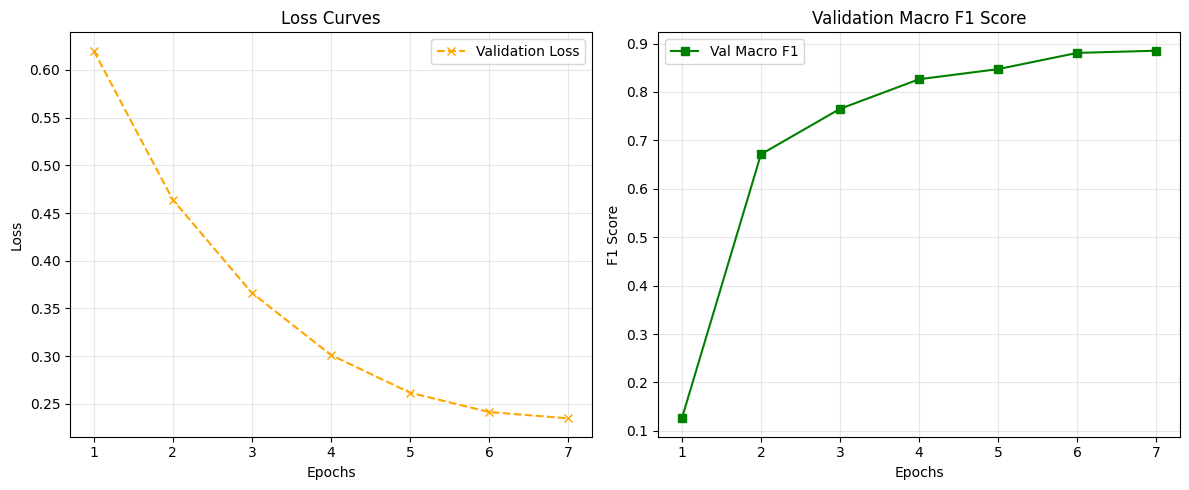

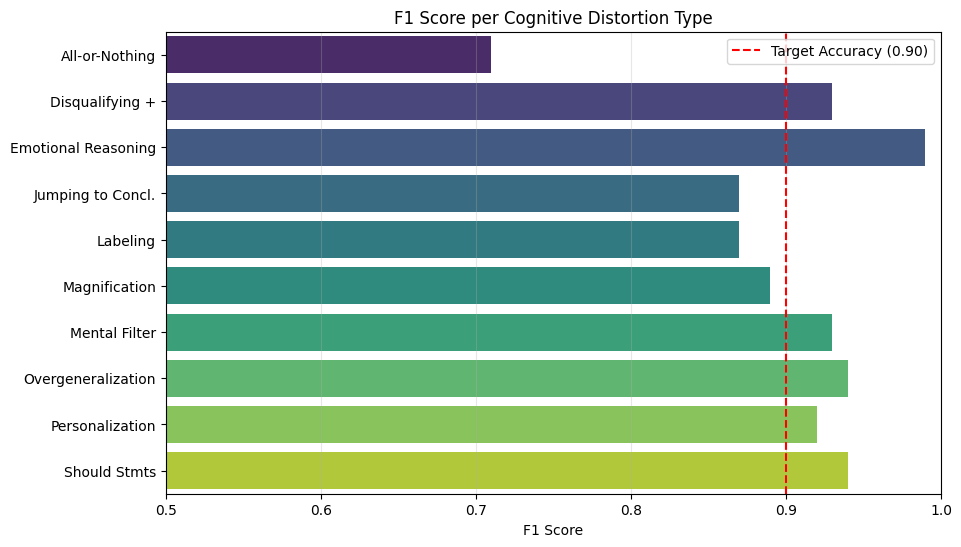

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# --- 1. SAFE DATA EXTRACTION ---
history = trainer.state.log_history

# Extract Training Data (Handle case where it's empty)
train_logs = [x for x in history if 'loss' in x]
if train_logs:
    df_train = pd.DataFrame(train_logs)
else:
    df_train = pd.DataFrame(columns=['epoch', 'loss']) # Create empty to prevent crash

# Extract Validation Data
val_logs = [x for x in history if 'eval_loss' in x]
df_val = pd.DataFrame(val_logs)

# --- 2. VISUALIZATION ---
plt.figure(figsize=(12, 5))

# Subplot 1: Loss
plt.subplot(1, 2, 1)
# Only plot training loss if we actually have it
if not df_train.empty and 'loss' in df_train.columns:
    plt.plot(df_train['epoch'], df_train['loss'], label='Training Loss', marker='o')
else:
    print("⚠️ Note: No training loss recorded yet (logging_steps not reached). Plotting validation only.")

# Plot validation loss (We know this exists)
if not df_val.empty:
    plt.plot(df_val['epoch'], df_val['eval_loss'], label='Validation Loss', marker='x', linestyle='--', color='orange')

plt.title('Loss Curves')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

# Subplot 2: Macro F1 (Validation Only)
plt.subplot(1, 2, 2)
if not df_val.empty and 'eval_macro_f1' in df_val.columns:
    plt.plot(df_val['epoch'], df_val['eval_macro_f1'], color='green', marker='s', label='Val Macro F1')
    plt.title('Validation Macro F1 Score')
    plt.xlabel('Epochs')
    plt.ylabel('F1 Score')
    plt.legend()
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# --- 3. BAR CHART (Hardcoded from your final results) ---
# This part is safe to run as-is
classes = [
    "All-or-Nothing", "Disqualifying +", "Emotional Reasoning", 
    "Jumping to Concl.", "Labeling", "Magnification", 
    "Mental Filter", "Overgeneralization", "Personalization", "Should Stmts"
]
f1_scores = [0.71, 0.93, 0.99, 0.87, 0.87, 0.89, 0.93, 0.94, 0.92, 0.94]

plt.figure(figsize=(10, 6))
sns.barplot(x=f1_scores, y=classes, hue=classes, palette="viridis", legend=False)
plt.axvline(x=0.9, color='r', linestyle='--', label='Target Accuracy (0.90)')
plt.title('F1 Score per Cognitive Distortion Type')
plt.xlabel('F1 Score')
plt.xlim(0.5, 1.0) 
plt.legend()
plt.grid(axis='x', alpha=0.3)
plt.show()

load it back

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Path to your uploaded model folder (unzipped)
model_path = "/kaggle/input/my-cbt-model/cbt_synthetic_pretrained" 

# 1. Load YOUR Tokenizer (Not the generic one)
tokenizer = AutoTokenizer.from_pretrained(model_path)

# 2. Load YOUR Pre-trained Model
model = AutoModelForSequenceClassification.from_pretrained(
    model_path,
    num_labels=11,               # Ensure this matches your original config
    problem_type="multi_label_classification",
    trust_remote_code=True
)

print("✅ Successfully loaded the Synthetic-Trained model!")
print("Ready to fine-tune on Real Data.")

In [ ]:
# =========================================================
# STEP 3: THRESHOLD TUNING & FINAL REPORT
# (Run this after training)
# =========================================================
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, precision_score, recall_score, classification_report

# 1. TUNING ON VALIDATION SET (Strictly separate from Test)
print("Predicting on Validation Set for Tuning...")
val_pred = trainer.predict(val_ds)
val_probs = 1 / (1 + np.exp(-val_pred.predictions))
Y_val = np.stack(val_df["labels"].to_numpy()).astype(int)

print("Finding optimal thresholds per label...")
thr = np.zeros(num_labels, dtype=np.float32)
for j in range(num_labels):
    best_t, best_f1 = 0.5, -1.0
    # Search from 0.05 to 0.95
    for t in np.arange(0.05, 0.95, 0.05):
        pj = (val_probs[:, j] >= t).astype(int)
        f1j = f1_score(Y_val[:, j], pj, zero_division=0)
        if f1j > best_f1:
            best_f1, best_t = float(f1j), float(t)
    thr[j] = best_t

print("\n" + "-"*40)
print("Optimized Thresholds per Label:")
for name, t in zip([id2label[i] for i in range(num_labels)], thr):
    print(f"  {name}: {t:.2f}")
print("-"*40)

# 2. FINAL PREDICTION ON TEST SET (Using Tuned Thresholds)
print("\nPredicting on Test Set...")
test_pred = trainer.predict(test_ds)
test_probs = 1 / (1 + np.exp(-test_pred.predictions))
Y_test = np.stack(test_df["labels"].to_numpy()).astype(int)

# Apply the custom thresholds we just found
test_hat = (test_probs >= thr).astype(int)

# 3. CALCULATE GLOBAL METRICS
modernbert_result = {
    "model": "ModernBERT (Tuned Thresholds)",
    "macro_f1": f1_score(Y_test, test_hat, average="macro", zero_division=0),
    "micro_f1": f1_score(Y_test, test_hat, average="micro", zero_division=0),
    "micro_precision": precision_score(Y_test, test_hat, average="micro", zero_division=0),
    "micro_recall": recall_score(Y_test, test_hat, average="micro", zero_division=0),
    "pred_pos": int(test_hat.sum()),
    "true_pos": int(Y_test.sum())
}

print("\n" + "="*50)
print("FINAL RESULTS SUMMARY")
print("="*50)
print(modernbert_result)

# 4. GENERATE DETAILED CLASSIFICATION REPORT
target_names = [id2label[i] for i in range(num_labels)]

print("\n" + "="*50)
print("DETAILED CLASSIFICATION REPORT")
print("="*50)
report_text = classification_report(
    Y_test,
    test_hat,
    target_names=target_names,
    zero_division=0,
    digits=4
)
print(report_text)

# Save to CSV for your Thesis
report_dict = classification_report(
    Y_test,
    test_hat,
    target_names=target_names,
    zero_division=0,
    output_dict=True
)
df_report = pd.DataFrame(report_dict).transpose()
df_report.to_csv("/kaggle/working/modernbert_tuned_report.csv")
print("\n✅ Saved report to: /kaggle/working/modernbert_tuned_report.csv")

Predicting on Validation Set for Tuning...


/usr/local/lib/python3.12/dist-packages/torch/nn/parallel/_functions.py:71: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  warnings.warn(


Finding optimal thresholds per label...

----------------------------------------
Optimized Thresholds per Label:
  All-or-Nothing Thinking: 0.50
  Disqualifying the Positive: 0.55
  Emotional Reasoning: 0.55
  Jumping to Conclusions: 0.30
  Labeling: 0.45
  Magnification or Minimization: 0.50
  Mental Filter: 0.35
  Overgeneralization: 0.60
  Personalization: 0.60
  Should Statements: 0.30
----------------------------------------

Predicting on Test Set...


/usr/local/lib/python3.12/dist-packages/torch/nn/parallel/_functions.py:71: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  warnings.warn(


In [ ]:
args = TrainingArguments(
    output_dir = "/kaggle/working/modernbert_output", # <--- CRITICAL CHANGE
    # ... rest of your args
)